# A3 · In Vivo Spin Physics

**Part:** A – Physics of the MRI signal · **Reading time:** ~55 min · **Pass 1 overview:** [What MRI measures](../pass1_big_picture/P1.1_What_MRI_Measures.ipynb), [Speed, artifacts and safety](../pass1_big_picture/P1.5_Speed_Artifacts_and_Safety.ipynb) · **Refreshers you may want:** [Magnetism from currents](../refreshers/RP1_Magnetism_from_Currents.ipynb), [Complex numbers and rotations](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb)

In living tissue, several spin-physics phenomena change the MRI signal. The two most important are **magnetic susceptibility** differences (tissue, air, blood, iron and metal magnetize differently and distort the field) and **chemical shift** (protons in fat resonate at a slightly different frequency than protons in water). Both shift the resonance frequency by a few parts per million (ppm)—which at 3 T means tens to thousands of Hz. These shifts cause signal loss and image distortion, but they are also exploited: BOLD functional MRI, susceptibility-weighted imaging, fat–water separation. Other phenomena (flow, diffusion, magnetization transfer) are covered elsewhere ([D2](../pass2_deep_dive/D2_In_Vivo_Contrast_Mechanisms.ipynb)).

## Learning goals

1. Describe the concepts of polarization, resonance, excitation, and relaxation
    * Describe the concept of magnetic susceptibility (dia-, para-, ferromagnetism) and give typical values
    * Describe how magnetic susceptibility differences affect resonance; estimate $\Delta B_0\sim\chi B_0$ and compute the field around a sphere and a cylinder
    * Describe the concept of chemical shift (shielding, ppm)
    * Describe how chemical shift differences affect resonance; compute fat–water frequency differences and in-/opposed-phase echo times at 1.5 and 3 T
1. Combine all sources into the off-resonance $\Delta f(\vec r)$ used in the signal equation ([C2](../pass2_deep_dive/C2_MRI_Signal_Equation.ipynb))

## Symbols used in this chapter

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $\vec r=[x,y,z]^T$, $r$ | position; distance from the centre of an object | m | |
| $\vartheta$ | angle between the position vector (from the centre of a sphere) and $B_0$ | rad | |
| $\theta_c$, $\varphi$ | angle of a cylinder's axis with $B_0$; azimuth around the cylinder | rad | |
| $a$ | radius of a sphere or cylinder | m | |
| $B_0$ | main static field (along $z$) | T | 1.5, 3, 7 T |
| $\Delta B_0(\vec r)$ | deviation of the static field from $B_0$ | T | ppm of $B_0$ |
| $B_{eff}$ | field actually felt by a nucleus (here: after electron shielding) | T | |
| $\vec H$ | magnetic field strength ("H-field") | A/m | $B=\mu_0(H+M)$ |
| $\vec M_{ind}$ | magnetization *induced in a material* (electron magnetism, not nuclear) | A/m | $M_{ind}=\chi H$ |
| $\chi$, $\Delta\chi$ | (volume, SI) magnetic susceptibility; difference between two materials | – (often in ppm) | water $-9.05\times10^{-6}$ |
| $\mu_0$ | vacuum permeability | T m/A | $4\pi\times10^{-7}$ |
| $\sigma$ | chemical shielding constant (in this chapter only!) | – | ~$10^{-5}$ |
| $\delta_{cs}$ | chemical shift relative to water, in ppm (×10⁻⁶) | – | fat ≈ −3.5 ppm |
| $\gamma$, $\bar\gamma$ | gyromagnetic ratio | rad s⁻¹ T⁻¹; Hz/T | 42.58 MHz/T |
| $f_0=\bar\gamma B_0$ | Larmor frequency | Hz | 127.7 MHz @3 T |
| $\Delta f(\vec r)$ | total off-resonance frequency | Hz | |
| $\Delta f_r(\vec r)=\bar\gamma\Delta B_0(\vec r)$ | off-resonance due to field inhomogeneity/susceptibility | Hz | |
| $\Delta f_{cs}=\delta_{cs}\bar\gamma B_0$ | chemical-shift frequency offset | Hz | fat: −224 Hz @1.5 T, −447 Hz @3 T |
| $t$, $TE$ | time after excitation; echo time | s | |
| $\phi$ | phase of $M_{xy}$ | rad | |
| $Y$ | oxygen saturation of blood | – | arterial ~0.98, venous ~0.6 |
| $Hct$ | haematocrit (volume fraction of red blood cells) | – | ~0.4 |
| $\zeta$ | blood volume fraction in a voxel | – | 2–5 % |
| $T_2^*$, $T_2'$ | effective transverse relaxation time; dephasing part, $1/T_2^*=1/T_2+1/T_2'$ | s | |
| $FF$ | fat fraction of a voxel | – | 0–1 |
| $W$, $F$ | water and fat signal of a voxel | a.u. | |
| $BW_{read}/N_{read}$ | receiver bandwidth per pixel | Hz/pixel | 100–500 Hz |

> **⚠️ Common confusion:** $\sigma$ here is the chemical shielding constant, not noise or conductivity; $\delta_{cs}$ is the chemical shift in ppm, not the pixel size $\delta$ or a Dirac delta. And the **induced electronic magnetization** $\vec M_{ind}$ of a material (which distorts the field) is a different thing from the **nuclear** magnetization $\vec M$ we image—although both are measured in A/m.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1 Magnetic susceptibility

### 1.1 Definition

The **magnetic susceptibility** $\chi$ measures how strongly a substance becomes magnetized when placed in a magnetic field. The *electrons* of the material (not the nuclei!) respond to the applied field and produce an induced magnetization

$$\vec M_{ind}=\chi\,\vec H,\qquad \vec B=\mu_0(\vec H+\vec M_{ind})=\mu_0(1+\chi)\vec H$$

In words: a material in a field becomes slightly magnetized in proportion to the field; the total field inside it is changed by the fraction $\chi$.

where $\vec H$ [A/m] is the field strength ($\vec B=\mu_0\vec H$ in vacuum), $\vec M_{ind}$ [A/m] the induced magnetization and $\chi$ the dimensionless (SI, volume) susceptibility. Because $\chi$ is tiny for most tissues it is quoted in **ppm** ($10^{-6}$). Most importantly for MRI, tissue becomes magnetized when placed in the scanner, and the field it produces adds to $B_0$.

Substances are classified into three types:

1. **Diamagnetic** substances ($\chi<0$): the applied field slightly modifies the orbital motion of paired electrons, which produces a weak field *opposing* $B_0$ (a molecular version of Lenz's law). The field inside is slightly reduced. They are essentially "non-magnetic". Water and the vast majority of tissues are diamagnetic, $\chi\approx-9$ ppm.
2. **Paramagnetic** substances ($\chi>0$): they contain *unpaired* electrons whose magnetic moments partially align with the field (just like nuclear spins in [A1](../pass2_deep_dive/A1_Spin_Physics.ipynb), but an electron's moment is ~660× larger than a proton's). They are magnetized only while the external field is on, in the same direction as $B_0$, increasing the local field. Examples: molecular oxygen (O₂, and therefore air), deoxyhaemoglobin, ferritin/haemosiderin iron, and the Gd³⁺ ion in gadolinium-based contrast agents.
3. **Ferromagnetic** substances ($\chi\gg0$, often $10^2$–$10^5$): neighbouring electron moments lock together into domains that align with the field. They are strongly attracted by the magnet—**dangerous** in MRI (projectiles; [B6](../pass2_deep_dive/B6_MRI_Safety.ipynb))—saturate at fields far below 1 T, and can keep (part of) their magnetization after the field is removed (hysteresis: that is how permanent magnets are made). Examples at room temperature: iron (Fe), cobalt (Co), nickel (Ni) and many of their alloys.

> **⚠️ Common confusion:** metallic gadolinium is ferromagnetic only below ~20 °C, and the Gd³⁺ ion in contrast agents is paramagnetic. Likewise, iron *in tissue* (ferritin, haemosiderin, haemoglobin) is paramagnetic or superparamagnetic, not ferromagnetic as the original text states—only bulk metallic iron is ferromagnetic.

### 1.2 Typical values

Approximate SI volume susceptibilities (literature values, mainly from J. F. Schenck, *Med. Phys.* 23:815, 1996; tissue values vary by ±20 %):

| Material | $\chi$ [ppm] | Type | $\Delta\chi$ vs water [ppm] |
|---|---|---|---|
| water (37 °C) | −9.05 | dia | 0 |
| most soft tissues | −11 to −7 | dia | ±2 |
| fat | ≈ −8 | dia | ≈ +1 |
| cortical bone | ≈ −11 | dia | ≈ −2 |
| air | +0.36 | para (O₂) | **+9.4** |
| deoxygenated minus oxygenated blood (per unit $Hct$) | +0.27 | para | — |
| Gd-chelate contrast agent | ≈ +0.3 per mM | para | ~1–3 during a bolus |
| titanium | ≈ +180 | para | ≈ +190 |
| austenitic stainless steel | ~$10^3$–$10^4$ | para / weakly ferro (grade, cold work) | large |
| iron, nickel, cobalt | ≫ 1 | ferro | huge |

Magnetic susceptibility changes the field in the vicinity of the substance—inside it, but also in surrounding tissues. In particular, there can be significant distortions of the field at the boundary between two substances with different susceptibilities. These field changes shift the resonance frequency, and they cause dephasing within a voxel that shortens $T_2^*$ (Section 2.3 and [D3](../pass2_deep_dive/D3_Gradient_and_Spin_Echoes.ipynb)).

### 1.3 Scaling: $\Delta B_0\sim\Delta\chi\,B_0$

The induced magnetization is proportional to the applied field, so the *field disturbance* is proportional to $B_0$ and to the susceptibility difference, times a geometry factor of order 1:

$$\Delta B_0(\vec r)\approx \Delta\chi\cdot B_0\cdot g(\vec r)\qquad\Rightarrow\qquad\Delta f_r(\vec r)=\bar\gamma\,\Delta B_0(\vec r)\approx\Delta\chi\cdot f_0\cdot g(\vec r)$$

In words: a susceptibility difference of 1 ppm creates a field (and frequency) disturbance of the order of 1 ppm of $B_0$ (and of $f_0$); doubling $B_0$ doubles the disturbance in Hz.

where $g(\vec r)$ is a dimensionless shape factor (between about −1/3 and +2/3 for a sphere, see below). Since everything is "per ppm", the table below shows what 1 ppm means at different fields.

In [2]:
# What does a susceptibility-induced shift of 1 ppm (or the 9.4 ppm air-water difference) mean in Hz?
for B0 in [0.55, 1.5, 3.0, 7.0]:
    print(f"B0 = {B0:4.2f} T: f0 = {mt.larmor_frequency(B0)/1e6:6.2f} MHz | 1 ppm = {mt.ppm_to_hz(1, B0):6.1f} Hz | "
          f"air-water 9.4 ppm = {mt.ppm_to_hz(9.4, B0):7.0f} Hz")

B0 = 0.55 T: f0 =  23.42 MHz | 1 ppm =   23.4 Hz | air-water 9.4 ppm =     220 Hz
B0 = 1.50 T: f0 =  63.87 MHz | 1 ppm =   63.9 Hz | air-water 9.4 ppm =     600 Hz
B0 = 3.00 T: f0 = 127.73 MHz | 1 ppm =  127.7 Hz | air-water 9.4 ppm =    1201 Hz
B0 = 7.00 T: f0 = 298.04 MHz | 1 ppm =  298.0 Hz | air-water 9.4 ppm =    2802 Hz


Interpretation: at 3 T, 1 ppm is 128 Hz, and the full air–water susceptibility difference corresponds to ~1.2 kHz. Compared with typical readout bandwidths of 100–500 Hz per pixel, such shifts displace signal by several pixels and dephase it within milliseconds.

### 1.4 The field around a sphere and a cylinder (analytic dipole formulas)

Two shapes have simple closed-form solutions and are the workhorses for intuition (see e.g. Haacke et al., *Magnetic Resonance Imaging: Physical Principles and Sequence Design*; Ogawa et al., *Biophys. J.* 64:803, 1993). For a **sphere** of radius $a$ with susceptibility difference $\Delta\chi$ to its surroundings, the $z$-component of the field disturbance outside is that of a magnetic dipole:

$$\Delta B_z(r,\vartheta)=\frac{\Delta\chi}{3}\,B_0\,\Big(\frac{a}{r}\Big)^3\big(3\cos^2\vartheta-1\big),\qquad r>a$$

In words: the disturbance is strongest at the surface, falls off with the cube of distance, is *positive* along the $B_0$ direction (poles) and *negative*, half as large, around the "equator" (for $\Delta\chi>0$).

where $r$ [m] is the distance from the centre and $\vartheta$ the angle between the position vector and $B_0$. (Inside the sphere, the field felt by nuclei is uniform; after the so-called Lorentz-sphere correction the offset is zero.)

For an infinitely long **cylinder** (a good model of a blood vessel) of radius $a$ whose axis makes an angle $\theta_c$ with $B_0$:

$$\Delta B_z^{in}=\frac{\Delta\chi}{6}\,B_0\,(3\cos^2\theta_c-1),\qquad \Delta B_z^{out}(r,\varphi)=\frac{\Delta\chi}{2}\,B_0\,\sin^2\theta_c\,\Big(\frac{a}{r}\Big)^2\cos2\varphi$$

In words: inside the vessel the field is uniformly shifted depending on its orientation; outside, a four-leaf "clover" pattern decays with the square of the distance and vanishes for vessels parallel to $B_0$.

where $r$ is the distance from the axis and $\varphi$ the angle around the axis, measured from the projection of $B_0$ onto the plane perpendicular to the cylinder.

The cell below evaluates both for realistic cases at 3 T: an **air bubble** (1 cm radius) in water, like an air-filled sinus or a bowel gas pocket, and a **vein** perpendicular to $B_0$ filled with venous blood.

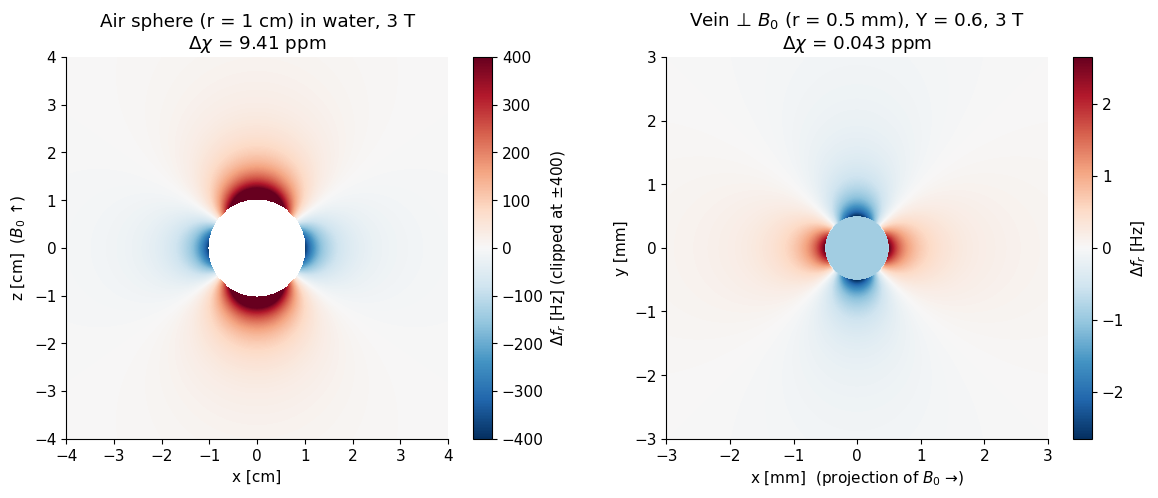

sphere: max 801 Hz at the poles, min -401 Hz at the equator
vein:   outside within ±2.65 Hz, inside -0.92 Hz


In [3]:
def sphere_dBz(X, Z, a, dchi, B0):
    """z-field offset [T] outside a sphere (radius a, susceptibility difference dchi) at points (X, Z), sphere at origin."""
    r = np.hypot(X, Z)
    cos2 = np.divide(Z**2, r**2, out=np.zeros_like(r), where=r > 0)
    dB = dchi / 3 * B0 * (a / np.maximum(r, 1e-12))**3 * (3*cos2 - 1)
    return np.where(r > a, dB, np.nan)          # NaN inside: no water spins in the bubble

def cylinder_dBz(X, Y, a, dchi, B0, theta_c=np.pi/2):
    """z-field offset [T] in the plane perpendicular to a cylinder (axis at angle theta_c to B0).
    The projection of B0 onto that plane is along X."""
    r = np.hypot(X, Y); phi = np.arctan2(Y, X)
    out = dchi / 2 * B0 * np.sin(theta_c)**2 * (a / np.maximum(r, 1e-12))**2 * np.cos(2*phi)
    inside = dchi / 6 * B0 * (3*np.cos(theta_c)**2 - 1)
    return np.where(r > a, out, inside)

B0 = 3.0
# Air bubble in water, x-z plane (B0 along z)
a_s, dchi_air = 0.01, 0.36e-6 - (-9.05e-6)
x = np.linspace(-0.04, 0.04, 401)
X, Z = np.meshgrid(x, x)
df_sphere = mt.GAMMA_BAR * sphere_dBz(X, Z, a_s, dchi_air, B0)          # Hz

# Vein (radius 0.5 mm) perpendicular to B0, venous blood Y = 0.6, Hct = 0.4
a_c, Hct, Y = 0.5e-3, 0.4, 0.6
dchi_vein = 0.27e-6 * Hct * (1 - Y)
xc = np.linspace(-3e-3, 3e-3, 401)
Xc, Yc = np.meshgrid(xc, xc)
df_cyl = mt.GAMMA_BAR * cylinder_dBz(Xc, Yc, a_c, dchi_vein, B0)        # Hz

fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
v = 400
im = ax[0].imshow(df_sphere, extent=[x[0]*100, x[-1]*100, x[0]*100, x[-1]*100], origin="lower", cmap="RdBu_r", vmin=-v, vmax=v)
ax[0].set_xlabel("x [cm]"); ax[0].set_ylabel(r"z [cm]  ($B_0$ ↑)"); ax[0].set_title(f"Air sphere (r = 1 cm) in water, 3 T\n$\\Delta\\chi$ = {dchi_air*1e6:.2f} ppm")
plt.colorbar(im, ax=ax[0], label=r"$\Delta f_r$ [Hz] (clipped at ±400)"); ax[0].grid(False)
v2 = np.nanmax(np.abs(df_cyl[np.hypot(Xc, Yc) > a_c]))
im2 = ax[1].imshow(df_cyl, extent=[xc[0]*1e3, xc[-1]*1e3, xc[0]*1e3, xc[-1]*1e3], origin="lower", cmap="RdBu_r", vmin=-v2, vmax=v2)
ax[1].set_xlabel(r"x [mm]  (projection of $B_0$ →)"); ax[1].set_ylabel("y [mm]")
ax[1].set_title(f"Vein ⊥ $B_0$ (r = 0.5 mm), Y = {Y}, 3 T\n$\\Delta\\chi$ = {dchi_vein*1e6:.3f} ppm")
plt.colorbar(im2, ax=ax[1], label=r"$\Delta f_r$ [Hz]"); ax[1].grid(False)
plt.tight_layout(); plt.show()
print(f"sphere: max {np.nanmax(df_sphere):.0f} Hz at the poles, min {np.nanmin(df_sphere):.0f} Hz at the equator")
print(f"vein:   outside within ±{v2:.2f} Hz, inside {df_cyl[200, 200]:.2f} Hz")

Interpretation: next to a 1 cm air pocket the frequency is shifted by up to +800 Hz (above and below, along $B_0$) and −400 Hz (beside it)—over a distance of a centimetre. This is why images near the sinuses, ear canals and bowel are distorted or show signal voids. The vein's disturbance is only a few Hz, but the brain is full of such vessels and their oxygenation changes with activity: this is the origin of the BOLD signal (Section 1.6).

### 1.5 From field maps to signal loss ($T_2'$)

A voxel (say 2 mm) near the air pocket contains a *range* of frequencies. Its signal is the average of the spins' phasors $e^{-i2\pi\Delta f_r(\vec r)t}$ over the voxel (the convention $M_{xy}\propto e^{-i2\pi\Delta f t}$ from [A2](../pass2_deep_dive/A2_Bloch_Equation.ipynb)). As $t$ grows the phasors fan out and cancel—**intravoxel dephasing**, an extra decay characterized by $T_2'$ with $1/T_2^*=1/T_2+1/T_2'$. We compute this for 2 mm × 2 mm voxels (2D cut, ignoring the third dimension and $T_2$ decay).

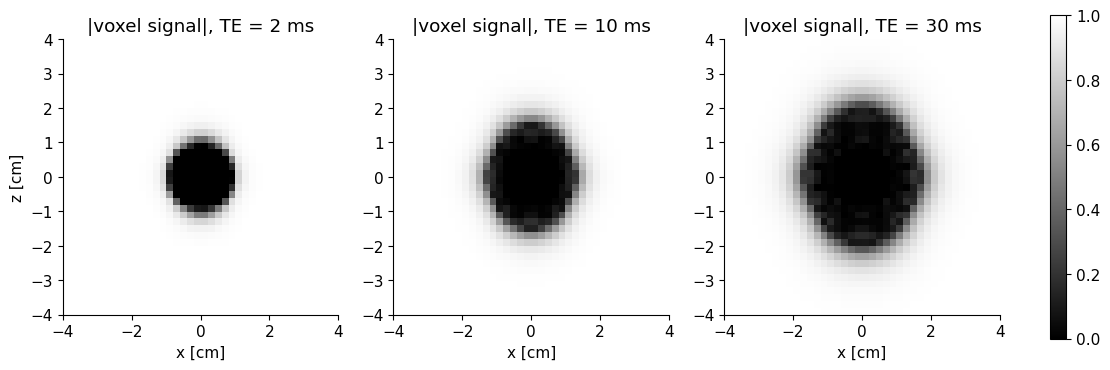

In [4]:
# Voxel-averaged signal |mean(exp(-i 2 pi df t))| over 2 mm x 2 mm voxels (each = 10 x 10 fine grid points of 0.2 mm)
fine = 10
n_vox = (len(x) - 1) // fine                      # 40 voxels per side
dff = df_sphere[:n_vox*fine, :n_vox*fine]
water = ~np.isnan(dff)
fig, ax = plt.subplots(1, 3, figsize=(13, 4.2))
for a_, TE in zip(ax, [2e-3, 10e-3, 30e-3]):
    phasor = np.where(water, np.exp(-1j * 2*np.pi * np.nan_to_num(dff) * TE), 0)
    S = phasor.reshape(n_vox, fine, n_vox, fine).mean(axis=(1, 3))          # average within each voxel
    im = a_.imshow(np.abs(S), extent=[-4, 4, -4, 4], origin="lower", cmap="gray", vmin=0, vmax=1)
    a_.set_title(f"|voxel signal|, TE = {TE*1e3:.0f} ms"); a_.set_xlabel("x [cm]"); a_.grid(False)
ax[0].set_ylabel("z [cm]"); plt.colorbar(im, ax=ax, fraction=0.02); plt.show()

Interpretation: at TE = 2 ms only the voxels touching the bubble lose signal; at 30 ms a dark "halo" several times larger than the bubble itself appears, elongated along $B_0$. This is the classic susceptibility artifact of gradient-echo imaging, worse at long TE, large voxels and high $B_0$. A spin echo refocuses this static dephasing ([D3](../pass2_deep_dive/D3_Gradient_and_Spin_Echoes.ipynb)).

> **🔧 Engineering reality:** scanners correct the *smooth* part of $\Delta B_0(\vec r)$ by **shimming**: extra coils (and the gradient offsets) that produce low-order spherical-harmonic field shapes, adjusted per patient in a few seconds. Typical scanners have 1st- and 2nd-order shims (9 terms); they cannot follow the sharp field changes at air–tissue interfaces, which vary over millimetres ([B3](../pass2_deep_dive/B3_Main_Magnet_Engineering.ipynb)). Remedies in the sequence: short TE, thin slices/small voxels, spin echoes, high readout bandwidth.

### 1.6 Important susceptibility effects in MRI

1. **Air–tissue interfaces.** Tissue is mostly water (slightly diamagnetic), air is slightly paramagnetic (O₂). The ~9.4 ppm difference causes strong field distortions at sinuses, ear canals, lungs and bowel, leading to signal loss and geometric distortion (Sections 1.4–1.5).
1. **Gadolinium-based contrast agents.** Gd³⁺ is paramagnetic with seven unpaired electrons. Its main effect is to *shorten the relaxation times* ($T_1$ and $T_2$) of nearby water wherever the agent goes, creating valuable contrast ([D2](../pass2_deep_dive/D2_In_Vivo_Contrast_Mechanisms.ipynb)); during a concentrated first-pass bolus its susceptibility effect also darkens $T_2^*$-weighted images (perfusion imaging).
1. **Blood-oxygen-level-dependent (BOLD) contrast.** Oxygenated haemoglobin is diamagnetic (close to tissue), **deoxyhaemoglobin is paramagnetic**. (Dissolved O₂ itself contributes little; it is the haemoglobin's oxygenation state that matters.) More deoxyhaemoglobin ⇒ larger $\Delta\chi$ between vessels and tissue ⇒ more dephasing ⇒ shorter $T_2^*$. Neural activity increases blood flow more than oxygen consumption, so venous blood becomes *more* oxygenated, $T_2^*$ lengthens, and the signal rises by ~1–5 % at 3 T. Functional MRI (fMRI) detects these changes.
1. **Tissue iron.** Iron accumulates in tissue as ferritin and haemosiderin, for example in haemochromatosis or haemosiderosis (liver, heart) and in deep brain nuclei with age. These are paramagnetic iron stores, which shorten $T_2$ and $T_2^*$ strongly—liver iron is quantified clinically via $R_2^*=1/T_2^*$.
1. **Implants.** Implants contain materials that can distort the field. Titanium (and many modern orthopaedic alloys) is non-ferromagnetic and usually safe, but its susceptibility (~+180 ppm, i.e. ~20× that of water, with the opposite sign) still produces signal voids and distortions. Austenitic stainless steel is nominally non-ferromagnetic but has much larger susceptibility and can become partly ferromagnetic when cold-worked. Other implants contain ferromagnetic components, which pose a **safety** risk (force, torque, heating). It is crucial to check the MR safety of any implant before a scan ([B6](../pass2_deep_dive/B6_MRI_Safety.ipynb)).

### 1.7 Simple BOLD simulation (static dephasing around vessels)

Model a voxel as many identical unit cells, each containing one vein perpendicular to $B_0$ occupying a fraction $\zeta=3\,\%$ of the area. We compute the extravascular signal $S(TE)=\langle e^{-i2\pi\Delta f_r(\vec r)TE}\rangle$ for venous oxygenation $Y=0.6$ (rest) and $Y=0.7$ (activation) at 3 T. (This ignores diffusion, the intravascular signal and the spread of vessel orientations, so it only captures the basic mechanism.)

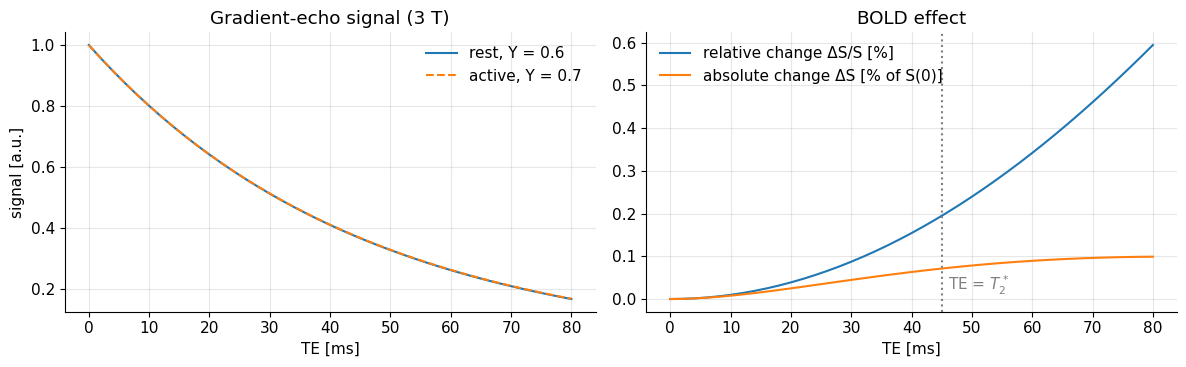

In [5]:
def bold_extravascular_signal(Y, TE, B0=3.0, zeta=0.03, Hct=0.4, n=601):
    """Mean phasor of tissue around one vein (axis perpendicular to B0) in a square unit cell of blood fraction zeta."""
    a = 1.0                                   # vessel radius (arbitrary length unit; only ratios matter)
    L = a * np.sqrt(np.pi / zeta)             # side of the unit cell: pi a^2 / L^2 = zeta
    u = np.linspace(-L/2, L/2, n)
    X, Yg = np.meshgrid(u, u)
    tissue = np.hypot(X, Yg) > a
    df = mt.GAMMA_BAR * cylinder_dBz(X, Yg, a, 0.27e-6*Hct*(1 - Y), B0)[tissue]   # Hz
    return np.array([np.mean(np.exp(-1j*2*np.pi*df*te)) for te in np.atleast_1d(TE)])

TE = np.linspace(0, 80e-3, 41)
T2s_tissue = 0.045                            # s, typical gray-matter T2* at 3 T (other dephasing sources)
S_rest = np.abs(bold_extravascular_signal(0.6, TE)) * np.exp(-TE/T2s_tissue)
S_act  = np.abs(bold_extravascular_signal(0.7, TE)) * np.exp(-TE/T2s_tissue)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(TE*1e3, S_rest, label="rest, Y = 0.6"); ax[0].plot(TE*1e3, S_act, "--", label="active, Y = 0.7")
ax[0].set_xlabel("TE [ms]"); ax[0].set_ylabel("signal [a.u.]"); ax[0].set_title("Gradient-echo signal (3 T)"); ax[0].legend()
ax[1].plot(TE*1e3, 100*(S_act - S_rest)/S_rest, label="relative change ΔS/S [%]")
ax[1].plot(TE*1e3, 100*(S_act - S_rest)/S_rest.max(), label="absolute change ΔS [% of S(0)]")
ax[1].axvline(T2s_tissue*1e3, color="gray", ls=":"); ax[1].text(T2s_tissue*1e3+1, 0.02, r"TE = $T_2^*$", color="gray")
ax[1].set_xlabel("TE [ms]"); ax[1].set_title("BOLD effect"); ax[1].legend(); plt.tight_layout(); plt.show()

Interpretation: making the venous blood more oxygenated reduces dephasing, so the active signal is slightly higher. The relative change grows with TE, but the signal itself decays; the *absolute* change peaks near TE ≈ $T_2^*$ (~30–45 ms at 3 T)—exactly the TE used in fMRI. This crude static model gives a few tenths of a percent; measured BOLD changes (1–5 %) are larger because blood volume also increases and intravascular signal and many vessel sizes/orientations contribute.

## 2 Chemical shift

### 2.1 Shielding

A fundamental concept in magnetic resonance and NMR spectroscopy is **chemical shift**: the resonance frequency of a nucleus depends slightly on its chemical environment. The cause is **shielding**: the applied field makes the electrons around the nucleus circulate (the same diamagnetic effect as in Section 1), and this electron current produces a small field *opposing* $B_0$ at the nucleus. The field felt by the nucleus is therefore

$$B_{eff}=B_0\,(1-\sigma)$$

In words: the nucleus feels a field reduced by a tiny fraction $\sigma$ because the surrounding electrons partly shield it.

where $\sigma$ (dimensionless, order $10^{-5}$ for protons) is the **shielding constant**, which depends on the local chemical environment: for example, a specific atom in a molecule has a shielding constant that depends on the electrons of the surrounding atoms (electronegative neighbours such as oxygen pull electrons away and *de*shield the proton). (The original writes $B_0(1+\sigma)$; with the usual definition of $\sigma>0$ as shielding, the sign is minus.)

The **chemical shift** $\delta_{cs}$ is defined with respect to a reference frequency $f_{ref}$, typically the resonance of a standard molecule (in NMR: tetramethylsilane, TMS; in MRI: water), in parts per million:

$$\delta_{cs}=\frac{f-f_{ref}}{f_{ref}}\times10^6\ \text{ppm}\approx(\sigma_{ref}-\sigma)\times10^6$$

In words: the chemical shift is the relative frequency difference to the reference, in millionths; it is (approximately) the difference of the shielding constants, so it does **not** depend on $B_0$.

The resulting frequency offset *does* scale with the field:

$$\Delta f_{cs}=\delta_{cs}\,\bar\gamma\,B_0$$

In words: the frequency shift in Hz is the shift in ppm (×10⁻⁶) times the Larmor frequency.

where $\delta_{cs}$ is used as a plain number (e.g. $-3.5\times10^{-6}$).

### 2.2 Fat versus water

In MRI, chemical shift mostly matters because of the difference between **fat** and **water** protons. Fat consists of triglycerides (lipids) whose protons sit in several chemical groups, giving a relatively complex spectrum that also varies with the type of lipid. In MRI a generic "fat" signal is often modelled as a **single peak at −3.5 ppm** relative to water (the dominant methylene –CH₂– group at 1.3 ppm vs water at 4.7 ppm on the TMS scale; some vendors use −3.4 ppm). Fat precesses *slower* than water.

In [6]:
# Fat-water frequency difference at common field strengths
for B0 in [0.55, 1.5, 3.0, 7.0]:
    print(f"B0 = {B0:4.2f} T: Delta f_cs(fat) = {mt.ppm_to_hz(mt.FAT_SHIFT_PPM, B0):8.1f} Hz")

B0 = 0.55 T: Delta f_cs(fat) =    -82.0 Hz
B0 = 1.50 T: Delta f_cs(fat) =   -223.5 Hz
B0 = 3.00 T: Delta f_cs(fat) =   -447.1 Hz
B0 = 7.00 T: Delta f_cs(fat) =  -1043.1 Hz


Interpretation: about −224 Hz at 1.5 T and −447 Hz at 3 T (the original quotes 220 and 440 Hz). It grows linearly with $B_0$, which makes fat suppression easier (better separated peaks) but chemical-shift artifacts larger at high field.

A more accurate **multi-peak fat model** (six peaks, widely used for liver fat quantification, e.g. Hamilton et al., *NMR Biomed.* 2011, and the ISMRM fat–water toolbox) is plotted below as a spectrum. The NMR convention plots ppm decreasing to the right.

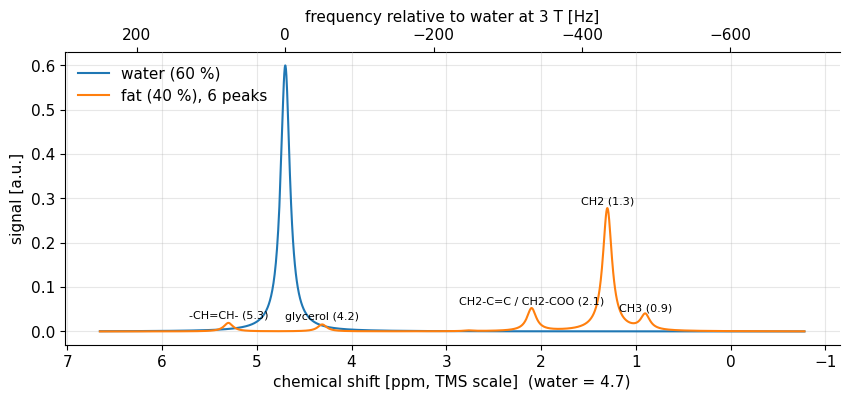

In [7]:
# Six-peak fat model: chemical shift relative to water [ppm] and relative amplitudes (sum = 1)
fat_ppm = np.array([-3.80, -3.40, -2.60, -1.94, -0.39, 0.60])
fat_amp = np.array([0.087, 0.693, 0.128, 0.004, 0.039, 0.048])
fat_names = ["CH3 (0.9)", "CH2 (1.3)", "CH2-C=C / CH2-COO (2.1)", "C=C-CH2-C=C (2.76)", "glycerol (4.2)", "-CH=CH- (5.3)"]

def lorentzian(f, f_c, width):                # line shape with full width at half maximum "width" [Hz]
    return (width/2)**2 / ((f - f_c)**2 + (width/2)**2)

B0 = 3.0
f = np.linspace(-700, 250, 3000)              # Hz relative to water
lw = 15.0                                     # Hz linewidth (~1/(pi T2*) for T2* ~ 20 ms)
spec_w = lorentzian(f, 0, lw)
spec_f = sum(a * lorentzian(f, mt.ppm_to_hz(p, B0), lw) for p, a in zip(fat_ppm, fat_amp))
ppm_axis = f / mt.larmor_frequency(B0) * 1e6
plt.figure(figsize=(10, 3.8))
plt.plot(ppm_axis + 4.7, 0.6*spec_w, label="water (60 %)"); plt.plot(ppm_axis + 4.7, 0.4*spec_f, label="fat (40 %), 6 peaks")
for p, a, nm in zip(fat_ppm, fat_amp, fat_names):
    if a > 0.03: plt.annotate(nm, (p + 4.7, 0.4*a + 0.01), fontsize=8, ha="center")
plt.gca().invert_xaxis(); plt.xlabel("chemical shift [ppm, TMS scale]  (water = 4.7)"); plt.ylabel("signal [a.u.]")
sec = plt.gca().secondary_xaxis("top", functions=(lambda p: (p - 4.7)*1e-6*mt.larmor_frequency(B0), lambda h: h/mt.larmor_frequency(B0)*1e6 + 4.7))
sec.set_xlabel("frequency relative to water at 3 T [Hz]"); plt.legend(loc="upper left"); plt.show()

Interpretation: the main fat peak (–CH₂–, 69 % of fat protons) sits ~435–447 Hz below water at 3 T, but ~15 % of fat signal lies near or even above the water frequency. Those small peaks cannot be suppressed by a frequency-selective fat-saturation pulse and complicate fat–water separation.

### 2.3 Fat–water phase evolution and in-/opposed-phase echo times

After excitation, water and fat in the same voxel start in phase. In the rotating frame at the water frequency, fat precesses at $\Delta f_{cs}$ relative to water, so the voxel signal at echo time $TE$ (ignoring relaxation) is

$$S(TE)=W+F\,e^{-i2\pi\Delta f_{cs}TE}$$

In words: the water phasor stays still while the fat phasor rotates at the fat–water frequency difference; their sum oscillates in magnitude.

where $W$ and $F$ are the water and fat signals of the voxel. With $\Delta f_{cs}<0$ the fat phasor turns counter-clockwise ($e^{+i2\pi|\Delta f_{cs}|TE}$). The two are **opposed-phase** ("out of phase") when $|\Delta f_{cs}|TE=\tfrac12,\tfrac32,\dots$ and **in phase** when $|\Delta f_{cs}|TE=1,2,\dots$:

$$TE_{OP}=\frac{2n-1}{2|\Delta f_{cs}|},\qquad TE_{IP}=\frac{n}{|\Delta f_{cs}|},\qquad n=1,2,\dots$$

In words: opposed-phase echoes occur at odd multiples, in-phase echoes at even multiples, of half the fat–water period.

In [8]:
# In-phase and opposed-phase echo times (single-peak fat at -3.5 ppm)
for B0 in [1.5, 3.0]:
    dfc = abs(mt.ppm_to_hz(mt.FAT_SHIFT_PPM, B0))
    op = [(2*n - 1) / (2*dfc) * 1e3 for n in (1, 2, 3)]
    ip = [n / dfc * 1e3 for n in (1, 2, 3)]
    print(f"B0 = {B0} T (|df| = {dfc:.0f} Hz): opposed-phase TE = " + ", ".join(f"{v:.2f}" for v in op)
          + " ms;  in-phase TE = " + ", ".join(f"{v:.2f}" for v in ip) + " ms")

B0 = 1.5 T (|df| = 224 Hz): opposed-phase TE = 2.24, 6.71, 11.18 ms;  in-phase TE = 4.47, 8.95, 13.42 ms
B0 = 3.0 T (|df| = 447 Hz): opposed-phase TE = 1.12, 3.36, 5.59 ms;  in-phase TE = 2.24, 4.47, 6.71 ms


Interpretation: at 1.5 T the first opposed-/in-phase echoes are at 2.2 and 4.5 ms (clinical protocols typically use ~2.3 and ~4.6 ms); at 3 T everything is twice as fast: 1.1 and 2.2 ms.

The next cell plots $|S(TE)|$ for a voxel with 30 % fat, for the single-peak and six-peak models, plus snapshots of the water and fat phasors.

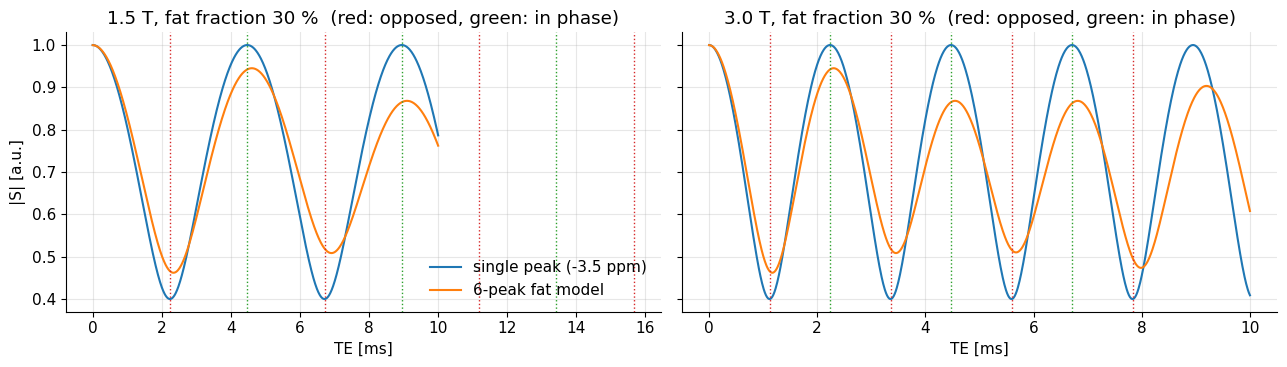

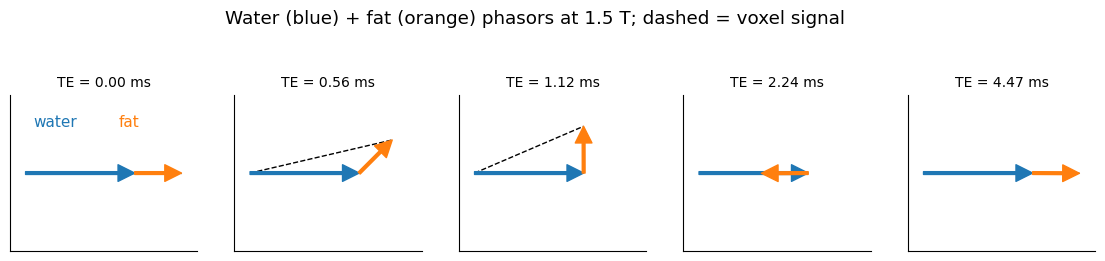

In [9]:
def fat_water_signal(TE, B0, FF, multipeak=True):
    """Voxel signal (rotating frame at water) for fat fraction FF; no relaxation."""
    TE = np.asarray(TE)
    if multipeak:
        fat = sum(a * np.exp(-1j*2*np.pi*mt.ppm_to_hz(p, B0)*TE) for p, a in zip(fat_ppm, fat_amp))
    else:
        fat = np.exp(-1j*2*np.pi*mt.ppm_to_hz(mt.FAT_SHIFT_PPM, B0)*TE)
    return (1 - FF) + FF * fat

TE = np.linspace(0, 10e-3, 1001)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for a_, B0 in zip(ax, [1.5, 3.0]):
    a_.plot(TE*1e3, np.abs(fat_water_signal(TE, B0, 0.3, False)), label="single peak (-3.5 ppm)")
    a_.plot(TE*1e3, np.abs(fat_water_signal(TE, B0, 0.3, True)), label="6-peak fat model")
    dfc = abs(mt.ppm_to_hz(mt.FAT_SHIFT_PPM, B0))
    for n in range(1, 8):
        a_.axvline(n/(2*dfc)*1e3, color="C3" if n % 2 else "C2", ls=":", lw=1)
    a_.set_title(f"{B0} T, fat fraction 30 %  (red: opposed, green: in phase)"); a_.set_xlabel("TE [ms]")
ax[0].set_ylabel("|S| [a.u.]"); ax[0].legend(loc="lower right"); plt.tight_layout(); plt.show()

# Phasor snapshots (single-peak model, 1.5 T)
fig, ax = plt.subplots(1, 5, figsize=(14, 3))
dfc = mt.ppm_to_hz(mt.FAT_SHIFT_PPM, 1.5)
for a_, te in zip(ax, [0, 0.56e-3, 1.12e-3, 2.24e-3, 4.47e-3]):
    w, fv = 0.7, 0.3*np.exp(-1j*2*np.pi*dfc*te)
    a_.annotate("", (w, 0), (0, 0), arrowprops=dict(color="C0", width=2))
    a_.annotate("", (w + fv.real, fv.imag), (w, 0), arrowprops=dict(color="C1", width=2))
    a_.plot([0, w + fv.real], [0, fv.imag], "k--", lw=1)
    a_.set_xlim(-0.1, 1.1); a_.set_ylim(-0.5, 0.5); a_.set_aspect("equal"); a_.set_title(f"TE = {te*1e3:.2f} ms", fontsize=10)
    a_.set_xticks([]); a_.set_yticks([])
ax[0].text(0.05, 0.3, "water", color="C0"); ax[0].text(0.6, 0.3, "fat", color="C1")
plt.suptitle("Water (blue) + fat (orange) phasors at 1.5 T; dashed = voxel signal", y=1.04); plt.show()

Interpretation: the signal of a mixed voxel oscillates with TE; at opposed-phase TEs fat cancels part of the water signal ($|S|=|W-F|=0.4$), at in-phase TEs they add ($|S|=W+F=1$). With the realistic six-peak model the in-phase echoes never fully recover and the minima are shallower—the reason quantitative fat imaging uses multi-peak models.

### 2.4 Application: in-/opposed-phase imaging and two-point Dixon

Clinically, an opposed-phase image shows a dark line ("India-ink" artifact) at every fat–water boundary, where voxels contain both, and loses signal in organs with microscopic fat (e.g. fatty liver, adrenal adenomas). Combining an in-phase (IP) and an opposed-phase (OP) image separates the two (the **Dixon** method, 1984): with the single-peak model, $S_{IP}=W+F$ and $S_{OP}=W-F$, so

$$W=\tfrac12(S_{IP}+S_{OP}),\qquad F=\tfrac12(S_{IP}-S_{OP})$$

In words: adding the two images cancels fat, subtracting cancels water.

Below we simulate this on the `mt.tissue_phantom` (its outer ring plays the role of subcutaneous fat) at 1.5 T. The phantom is defined on a fine grid and averaged into 4× coarser voxels so that boundary voxels contain both species.

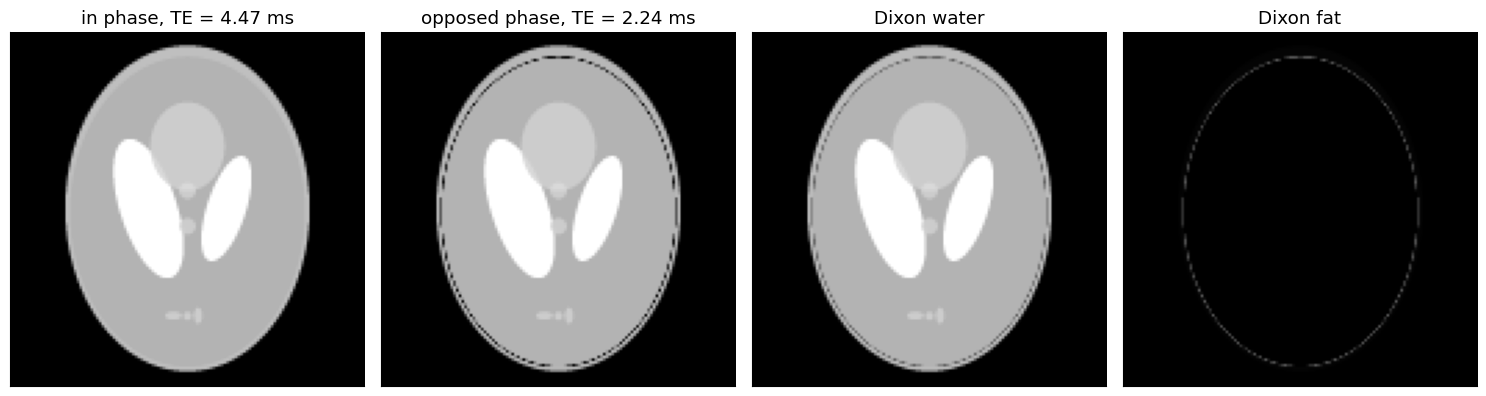

In [10]:
ph = mt.tissue_phantom(512)
is_fat = ph["labels"] == 1
W_fine = np.where(is_fat, 0, ph["M0"]); F_fine = np.where(is_fat, ph["M0"], 0)
def to_voxels(img, k=4):                      # average k x k fine pixels into one voxel (partial volume)
    n = img.shape[0] // k
    return img[:n*k, :n*k].reshape(n, k, n, k).mean(axis=(1, 3))

B0 = 1.5
dfc = abs(mt.ppm_to_hz(mt.FAT_SHIFT_PPM, B0))
TE_OP, TE_IP = 1/(2*dfc), 1/dfc
imgs = {}
for name, te in [("in phase", TE_IP), ("opposed phase", TE_OP)]:
    fat_term = sum(a*np.exp(-1j*2*np.pi*mt.ppm_to_hz(p, B0)*te) for p, a in zip(fat_ppm, fat_amp))   # realistic 6-peak fat
    imgs[name] = to_voxels(W_fine + F_fine * fat_term)
W_est = 0.5*(np.abs(imgs["in phase"]) + np.abs(imgs["opposed phase"]))   # magnitude Dixon (assumes W > F everywhere)
F_est = 0.5*(np.abs(imgs["in phase"]) - np.abs(imgs["opposed phase"]))
fig, ax = plt.subplots(1, 4, figsize=(15, 4))
for a_, (t_, im_) in zip(ax, [(f"in phase, TE = {TE_IP*1e3:.2f} ms", imgs["in phase"]), (f"opposed phase, TE = {TE_OP*1e3:.2f} ms", imgs["opposed phase"]),
                              ("Dixon water", W_est), ("Dixon fat", F_est)]):
    mt.show_image(im_, ax=a_, title=t_, vmin=0, vmax=1)
plt.tight_layout(); plt.show()

Interpretation: the opposed-phase image shows the dark India-ink rim at the inner and outer boundary of the "fat" ring, where voxels are part fat, part water. The Dixon combination separates water and fat, but because real fat is not a single peak a little fat (≈ 10–15 %) leaks into the "water" image—realistic Dixon methods fit multi-peak models with 3–6 echoes and also estimate the field map (IDEAL and related methods). Note also that the magnitude version used here cannot tell whether water or fat dominates a voxel.

### 2.5 Chemical-shift displacement (preview)

With frequency encoding ([F1](../pass2_deep_dive/F1_Spatial_Encoding.ipynb)), frequency means position. Fat, being off-resonant by $\Delta f_{cs}$, is therefore drawn displaced along the readout direction by

$$\Delta x_{cs}=\frac{\Delta f_{cs}}{BW_{read}/N_{read}}\ \text{pixels}$$

In words: the shift in pixels is the fat–water frequency difference divided by the receiver bandwidth per pixel.

In [11]:
for B0 in [1.5, 3.0, 7.0]:
    dfc = abs(mt.ppm_to_hz(mt.FAT_SHIFT_PPM, B0))
    print(f"B0 = {B0} T: fat shift = " + ", ".join(f"{dfc/bw:4.1f} px @ {bw} Hz/px" for bw in [100, 200, 400, 800]))

B0 = 1.5 T: fat shift =  2.2 px @ 100 Hz/px,  1.1 px @ 200 Hz/px,  0.6 px @ 400 Hz/px,  0.3 px @ 800 Hz/px
B0 = 3.0 T: fat shift =  4.5 px @ 100 Hz/px,  2.2 px @ 200 Hz/px,  1.1 px @ 400 Hz/px,  0.6 px @ 800 Hz/px
B0 = 7.0 T: fat shift = 10.4 px @ 100 Hz/px,  5.2 px @ 200 Hz/px,  2.6 px @ 400 Hz/px,  1.3 px @ 800 Hz/px


Interpretation: at 3 T with a typical 200 Hz/pixel, fat appears 2.2 pixels away from where it really is—visible as bright/dark bands at fat–water edges. Doubling the bandwidth halves the shift but costs $\sqrt2$ in SNR ([G2](../pass2_deep_dive/G2_Signal_to_Noise_Ratio.ipynb)). Echo-planar imaging, with its very low bandwidth in the phase-encoding direction, shifts fat by many pixels, so EPI always uses fat suppression ([I2 Artifacts](../pass2_deep_dive/I2_Artifacts.ipynb)).

## 3 Variations in the magnetic field: putting it together

In vivo MRI experiences changes of the longitudinal field, primarily from three sources. They are called **off-resonance** when they change the resonance frequency of the spins.

| Source | Typical size | at 3 T | Spatial character | Off-resonance type |
|---|---|---|---|---|
| main field $B_0$ inhomogeneity | < 1 ppm (after shimming ~0.1–0.5 ppm over an organ) | < 128 Hz | smooth | $\Delta f_r$ |
| magnetic susceptibility differences | up to ~10 ppm (air–tissue), much more near metal | up to ~1.3 kHz | sharp at interfaces | $\Delta f_r$ |
| chemical shift | fat −3.5 ppm | −447 Hz | depends on tissue type | $\Delta f_{cs}$ |

All of these change the $z$-component of the field, which we describe mathematically as

$$B_z(\vec r)=B_0+\Delta B_0(\vec r)+\delta_{cs}\,B_0$$

In words: the field that determines a spin's precession frequency is the main field plus a position-dependent imperfection plus a chemical-shift term that depends on the molecule.

where $\Delta B_0(\vec r)$ [T] includes both main-field imperfections and susceptibility effects, and $\delta_{cs}$ is the chemical shift of the species (0 for water, $-3.5\times10^{-6}$ for fat). (Strictly the chemical shift scales the *local* field, $B_0+\Delta B_0$, but $\Delta B_0\ll B_0$ so the difference is negligible.) Multiplying by $\bar\gamma$ and subtracting the rotating-frame frequency $f_0$ gives the total off-resonance

$$\Delta f(\vec r)=\bar\gamma B_z(\vec r)-f_0=\underbrace{\bar\gamma\Delta B_0(\vec r)}_{\Delta f_r(\vec r)}+\underbrace{\delta_{cs}\bar\gamma B_0}_{\Delta f_{cs}}$$

In words: the total frequency offset of a spin in the rotating frame is the sum of the field-inhomogeneity term and the chemical-shift term.

This $\Delta f(\vec r)$ enters the MRI signal equation as a phase $e^{-i2\pi\Delta f(\vec r)t}$ ([C2](../pass2_deep_dive/C2_MRI_Signal_Equation.ipynb)), and its consequences—distortion, blurring, signal loss, fat shifts—are analysed in [I2 Artifacts](../pass2_deep_dive/I2_Artifacts.ipynb).

> **🔧 Engineering reality:** everything in this chapter scales with $B_0$ in Hz: at 7 T, air–tissue shifts reach ~3 kHz and fat is 1 kHz from water. Higher fields give more SNR and better spectral separation (spectroscopy, fat suppression), but distortion and signal loss worsen and need higher bandwidth, stronger shims (3rd order at 7 T), and shorter TEs. This is one reason low-field systems (0.55 T) are attractive for imaging near implants and lungs.

## Key takeaways

* Tissues are weakly **diamagnetic** ($\chi\approx-9$ ppm); air, deoxyhaemoglobin, tissue iron and Gd³⁺ are **paramagnetic**; Fe/Co/Ni are **ferromagnetic** (dangerous).
* Susceptibility differences distort the field: $\Delta B_0\sim\Delta\chi\,B_0$ (ppm-scale; ~1.2 kHz for air–water at 3 T). Dipole formulas for a sphere ($\propto(a/r)^3(3\cos^2\vartheta-1)$) and a cylinder ($\propto(a/r)^2\cos2\varphi$) give the patterns.
* Intravoxel field variation dephases the signal (shorter $T_2^*$): signal voids near air and metal; BOLD contrast from deoxyhaemoglobin; iron quantification via $R_2^*$.
* **Chemical shift**: electron shielding $B_{eff}=B_0(1-\sigma)$; fat ≈ −3.5 ppm from water = −224 Hz (1.5 T), −447 Hz (3 T). Real fat has several peaks.
* Fat and water in one voxel interfere: opposed phase at TE = 2.2 ms (1.5 T) / 1.1 ms (3 T), in phase at 4.5 / 2.2 ms; Dixon methods use this to separate them.
* All sources combine into one off-resonance map $\Delta f(\vec r)=\bar\gamma\Delta B_0(\vec r)+\delta_{cs}\bar\gamma B_0$, which enters the signal equation.

## Check your understanding

1. A 7 T scan is planned near the frontal sinus. If the air–tissue shift at 3 T was 500 Hz at some point, what would it be at 7 T? And for fat?

<details><summary>Answer</summary>

Both scale with $B_0$: $500\times7/3\approx1170$ Hz; fat: $-3.5\times10^{-6}\times42.58\times10^6\times7\approx-1043$ Hz.

</details>

2. Is the field just above an air bubble (along $B_0$) higher or lower than far away? And beside it?

<details><summary>Answer</summary>

Air has $\Delta\chi=+9.4$ ppm relative to water. With $\vartheta=0$, $(3\cos^2\vartheta-1)=2>0$: the field is *higher* above and below (+6.3 ppm at the surface). Beside it ($\vartheta=90°$) the factor is −1: lower, by half as much (−3.1 ppm).

</details>

3. Why does a brain vein running parallel to $B_0$ produce no extravascular field disturbance in the cylinder model? What happens inside it?

<details><summary>Answer</summary>

For $\theta_c=0$, $\sin^2\theta_c=0$, so the outside disturbance vanishes. Inside, $\Delta B=\frac{\Delta\chi}{6}B_0(3-1)=\frac{\Delta\chi}{3}B_0$: the blood is uniformly shifted. BOLD therefore depends on vessel orientation.

</details>

4. Choose the first in-phase and opposed-phase echo times at 3 T. Why might a scanner choose the *second* opposed-phase echo instead?

<details><summary>Answer</summary>

Opposed 1.12 ms, in phase 2.24 ms. A TE of 1.1 ms may be too short for the gradient hardware to complete slice selection and the readout prephaser (and the readout itself); then the next opposed-phase echo, 3.35 ms, is used.

</details>

5. What is the shielding constant of a proton whose resonance is 3.5 ppm below water, relative to water?

<details><summary>Answer</summary>

$\delta_{cs}\approx\sigma_{water}-\sigma$, so $\sigma=\sigma_{water}+3.5\times10^{-6}$: it is *more* shielded by 3.5 ppm (fat's CH₂ protons have no electronegative oxygen neighbour pulling electron density away, unlike water's).

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapter "In Vivo Spin Physics". Changes: added definitions ($\chi$, $H$, induced magnetization), a table of susceptibilities, $\Delta B_0\sim\Delta\chi B_0$ scaling with Hz values, analytic sphere/cylinder field maps, voxel-dephasing and BOLD simulations, multi-peak fat spectrum, in-/opposed-phase TEs, Dixon and displacement demos. Corrected: shielding sign ($B_0(1-\sigma)$), tissue iron and Gd³⁺ are paramagnetic (not ferromagnetic), nuance on titanium/stainless steel implants, typos.*